In [3]:
!mamba install pandas numpy matplotlib seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 16.015 seconds
  Name          Version  Build                Channel
-------------------------------------------------------------------
+ pandas        3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
+ patsy         1.0.3    py313h1804a44_0      emscripten-forge-4x
+ seaborn       0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base  0.13.2   pyhd8ed1ab_3         conda-forge
+ six           1.17.0   pyhe01879c_1         conda-forge
+ statsmodels   0.15.0   np23py313h07ed413_0  emscripten-forge-4x
- pip           26.2.2   pyh145f28c_0         conda-forge


In [4]:
#PART1:  DATA PREPARATION 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv")

print("FIRST 5 ROWS: ")
print(df.head())
print("ROWS, COLUMNS")
print(df.shape)
print("DATA INFORMATION")
print(df.info())
print("SUM OF MISSING VALUES:")
print(df.isnull().sum())

FIRST 5 ROWS: 
  Make       Model  Year             Engine Fuel Type  Engine HP  \
0  BMW  1 Series M  2011  premium unleaded (required)      335.0   
1  BMW    1 Series  2011  premium unleaded (required)      300.0   
2  BMW    1 Series  2011  premium unleaded (required)      300.0   
3  BMW    1 Series  2011  premium unleaded (required)      230.0   
4  BMW    1 Series  2011  premium unleaded (required)      230.0   

   Engine Cylinders Transmission Type     Driven_Wheels  Number of Doors  \
0               6.0            MANUAL  rear wheel drive              2.0   
1               6.0            MANUAL  rear wheel drive              2.0   
2               6.0            MANUAL  rear wheel drive              2.0   
3               6.0            MANUAL  rear wheel drive              2.0   
4               6.0            MANUAL  rear wheel drive              2.0   

                         Market Category Vehicle Size Vehicle Style  \
0  Factory Tuner,Luxury,High-Performance      Co

In [5]:
#PART2:  EDA SUMMARY
for col in df.columns:
    print(f" Column: {col} ")
    print("No. OF UNIQUE VALUES:")
    print(df[col].nunique())
    print("SUM OF MISSING VALUES:")
    print(df[col].isnull().sum())
    print("\n")


 Column: Make 
No. OF UNIQUE VALUES:
48
SUM OF MISSING VALUES:
0


 Column: Model 
No. OF UNIQUE VALUES:
915
SUM OF MISSING VALUES:
0


 Column: Year 
No. OF UNIQUE VALUES:
28
SUM OF MISSING VALUES:
0


 Column: Engine Fuel Type 
No. OF UNIQUE VALUES:
10
SUM OF MISSING VALUES:
3


 Column: Engine HP 
No. OF UNIQUE VALUES:
356
SUM OF MISSING VALUES:
69


 Column: Engine Cylinders 
No. OF UNIQUE VALUES:
9
SUM OF MISSING VALUES:
30


 Column: Transmission Type 
No. OF UNIQUE VALUES:
5
SUM OF MISSING VALUES:
0


 Column: Driven_Wheels 
No. OF UNIQUE VALUES:
4
SUM OF MISSING VALUES:
0


 Column: Number of Doors 
No. OF UNIQUE VALUES:
3
SUM OF MISSING VALUES:
6


 Column: Market Category 
No. OF UNIQUE VALUES:
71
SUM OF MISSING VALUES:
3742


 Column: Vehicle Size 
No. OF UNIQUE VALUES:
3
SUM OF MISSING VALUES:
0


 Column: Vehicle Style 
No. OF UNIQUE VALUES:
16
SUM OF MISSING VALUES:
0


 Column: highway MPG 
No. OF UNIQUE VALUES:
59
SUM OF MISSING VALUES:
0


 Column: city mpg 
No. OF UNI

In [6]:
# Normalizing   column headers:
df.columns = df.columns.str.lower().str.replace(' ', '_')

print("Cleaned Column Names:")
print(df.columns.tolist())


Cleaned Column Names:
['make', 'model', 'year', 'engine_fuel_type', 'engine_hp', 'engine_cylinders', 'transmission_type', 'driven_wheels', 'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style', 'highway_mpg', 'city_mpg', 'popularity', 'msrp']


In [7]:
# Separate numerical columns
num_col = df.select_dtypes(include=['number']).columns.tolist()

# Separate categorical (text/object) columns
cat_col = df.select_dtypes(include=['object', 'category', 'str']).columns.tolist()

print("NUMERICAL COLUMNS (num_col):")
print(num_col)
print("\n CATEGORICAL COLUMNS (cat_col):")
print(cat_col)


NUMERICAL COLUMNS (num_col):
['year', 'engine_hp', 'engine_cylinders', 'number_of_doors', 'highway_mpg', 'city_mpg', 'popularity', 'msrp']

 CATEGORICAL COLUMNS (cat_col):
['make', 'model', 'engine_fuel_type', 'transmission_type', 'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style']


In [8]:
 # Handling all missing values 
df['engine_fuel_type'] = df['engine_fuel_type'].fillna(df['engine_fuel_type'].mode()[0])

df['engine_hp'] = df.groupby('make')['engine_hp'].transform(lambda x: x.fillna(x.median()))

df['engine_hp'] = df['engine_hp'].fillna(df['engine_hp'].median())

df['engine_cylinders'] = df['engine_cylinders'].fillna(df['engine_cylinders'].mode()[0])
df['number_of_doors'] = df['number_of_doors'].fillna(df['number_of_doors'].mode()[0])

df['market_category'] = df['market_category'].fillna('unknown')

print("SUM OF MISSING VALUES AFTER IMPUTATION:")
print(df.isnull().sum())



SUM OF MISSING VALUES AFTER IMPUTATION:
make                 0
model                0
year                 0
engine_fuel_type     0
engine_hp            0
engine_cylinders     0
transmission_type    0
driven_wheels        0
number_of_doors      0
market_category      0
vehicle_size         0
vehicle_style        0
highway_mpg          0
city_mpg             0
popularity           0
msrp                 0
dtype: int64


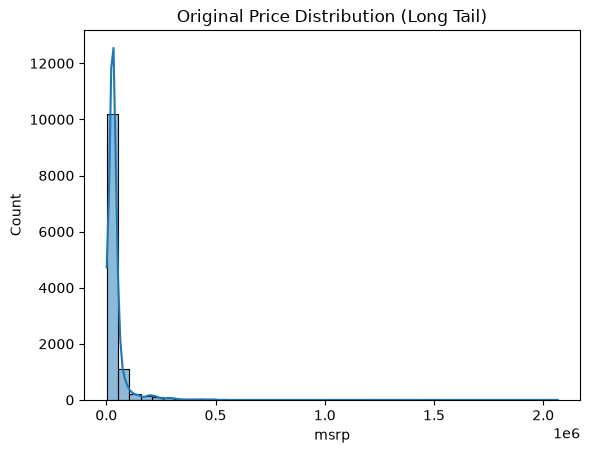

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot the original price distribution
sns.histplot(df['msrp'], bins=40, kde=True)
plt.title("Original Price Distribution (Long Tail)")
plt.show()


In [10]:
import numpy as np

# Create a new column with the log-transformed prices
df['msrp_log'] = np.log1p(df['msrp'])


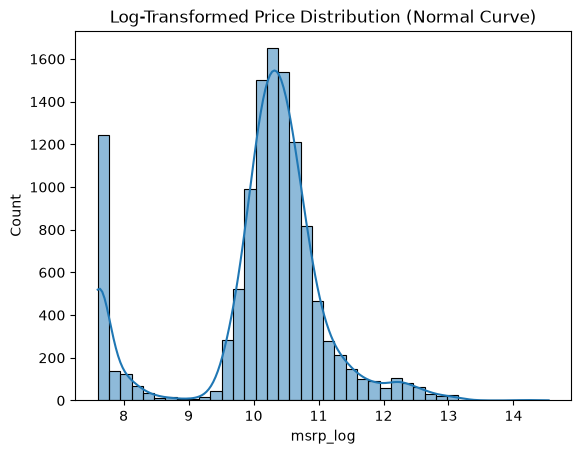

In [11]:
sns.histplot(df['msrp_log'], bins=40, kde=True)
plt.title("Log-Transformed Price Distribution (Normal Curve)")
plt.show()


In [13]:
# PART4: SETTING UP THE VALIDATION FRAMEWORK
import numpy as np

# 1. Define dataset size and slice lengths
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

# 2. Shuffle index records (with a seed for consistent results)
idx = np.arange(n)
np.random.seed(2)  
np.random.shuffle(idx)

# 3. Use the shuffled indices to split your original DataFrame
df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
df_val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
df_test = df.iloc[idx[n_train + n_val:]].reset_index(drop=True)

# 4. Verify the splits match up perfectly
print(f"Total Rows:      {n}")
print(f"Train Dataset:   {len(df_train)} rows")
print(f"Val Dataset:     {len(df_val)} rows")
print(f"Test Dataset:    {len(df_test)} rows")


Total Rows:      11914
Train Dataset:   7150 rows
Val Dataset:     2382 rows
Test Dataset:    2382 rows


In [14]:
 # Target Variable Extraction Code
import numpy as np

# 1. Extract and transform the target variables (y) using log(x + 1)
y_train = np.log1p(df_train['msrp'].values)
y_val = np.log1p(df_val['msrp'].values)
y_test = np.log1p(df_test['msrp'].values)

# 2. Drop the target variable from your feature dataframes (X) 
# This ensures your model can't accidentally "cheat" by looking at the answer!
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

# 3. Print confirmation of your shapes
print(" Target variable shapes:")
print(f"y_train: {y_train.shape}")
print(f"y_val:   {y_val.shape}")
print(f"y_test:  {y_test.shape}")


 Target variable shapes:
y_train: (7150,)
y_val:   (2382,)
y_test:  (2382,)


In [20]:
# PART5: LINEAR REGRESSION
# Single Car Prediction (Dot Product)
import numpy as np

# Synthetic example data for 1 car: [engine_hp, engine_cylinders, highway_mpg]
# Let's say: 275 HP, 6 cylinders, 26 MPG
xi = [275, 6, 26]

# Synthetic weights determined by a model (including bias at index 0)
w0 = 7.11
w = [0.004, -0.02, 0.001]

# Method A: Manual element-wise calculation
def linear_regression_single(xi, w0, w):
    prediction = w0
    for j in range(len(xi)):
        prediction += xi[j] * w[j]
    return prediction
# Call the function with your inputs and store the result
prediction_result = linear_regression_single(xi, w0, w)

print(f"Single Car Log Price Prediction: {prediction_result:.4f}")

real_price = np.expm1(prediction_result)
print(f"Single Car Real Price Prediction: {real_price:.4f}")


Single Car Log Price Prediction: 8.1160
Single Car Real Price Prediction: 3346.6035


In [24]:
# PART6: LINEAR REGRESSION VECTOR FORM
import numpy as np
w_new = [w0] + w
def linear_regression(xi):
    xi[1] + xi
    return dot(xi, w_new)

vector_prediction_result = linear_regression_single(xi, w0, w)
print(f"Single Car Log Price Prediction: {vector_prediction_result:.4f}")

real_price = np.expm1(vector_prediction_result)
print(f"Single Car Real Price Prediction: {real_price:.4f}")


Single Car Log Price Prediction: 8.1160
Single Car Real Price Prediction: 3346.6035


In [26]:
import numpy as np

# 1. Define the raw data for individual cars (engine_hp, engine_cylinders, highway_mpg)
car_1 = [275, 6, 26]
car_2 = [170, 4, 34]
car_3 = [425, 8, 18]

# 2. Add the bias feature (1) to the front of EACH individual car list
car_1_with_bias = [1] + car_1  # Result: [1, 275, 6, 26]
car_2_with_bias = [1] + car_2  # Result: [1, 170, 4, 34]
car_3_with_bias = [1] + car_3  # Result: [1, 425, 8, 18]

# 3. Put them together into a metric (a list of lists)
matrix_list = [
    car_1_with_bias,
    car_2_with_bias,
    car_3_with_bias
]

# 4. Turn the list of lists into a 2D NumPy array
X_matrix = np.array(matrix_list)

# --- Verification ---
print(" Raw List of Lists:")
print(matrix_list)

print("\n Two-Dimensional NumPy Array (X_matrix):")
print(X_matrix)

print("\n Shape of the Matrix:")
print(f"{X_matrix.shape[0]} cars (rows) by {X_matrix.shape[1]} features (columns)")

def linear_regression(X_matrix):
    return X_matrix.dot(w_new)

 Raw List of Lists:
[[1, 275, 6, 26], [1, 170, 4, 34], [1, 425, 8, 18]]

 Two-Dimensional NumPy Array (X_matrix):
[[  1 275   6  26]
 [  1 170   4  34]
 [  1 425   8  18]]

 Shape of the Matrix:
3 cars (rows) by 4 features (columns)


In [42]:
# PART7: TRAINING LINEAR REGRESSION
import numpy as np

# 1. Define the raw matrix (9 rows, 3 columns)
X_raw = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]
X_raw = np.array(X_raw)

# 2. Define your target labels
y = np.array([100, 200, 150, 250, 100, 200, 150, 250, 120])

# 3. Create the clean, standalone training function
def train_linear_regression(X, y):
    # This function takes RAW data, and adds the bias column cleanly inside
    ones = np.ones(X.shape)
    X_with_bias = np.column_stack([ones, X])

    # Normal Equation Step-by-Step
    XTX = X_with_bias.T.dot(X_with_bias)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X_with_bias.T).dot(y)

    # Return the bias weight (w0) and the feature weights (w) separately
    return w_full, w_full[1:]

# 4. Run the function using your raw matrix
w0, w = train_linear_regression(X_raw, y)

#  Print results
print(f"w0 (Baseline Bias weight): {w0[0]:.4f}")
print(f"w  (Weights for your 3 features): {w}")



w0 (Baseline Bias weight): nan
w  (Weights for your 3 features): [nan nan nan nan nan]


Feature Matrix Dimensions:
X_train_raw shape: (7150, 5) (Cars to train on, Baseline numeric features)
X_val_raw shape:   (2382, 5)  (Cars to validate on, Baseline numeric features)


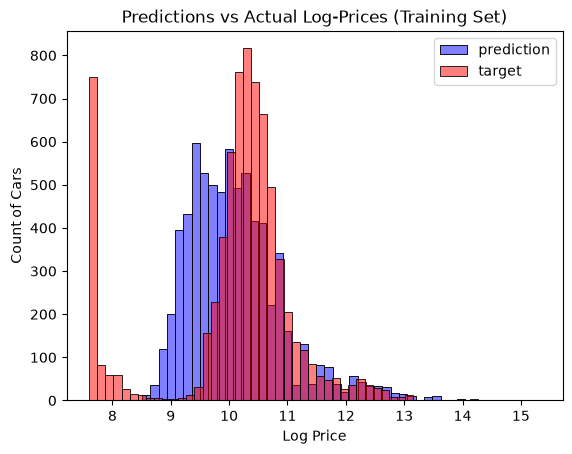

In [49]:
# PART8: BASELINE MODEL
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 0. A truly dynamic training function that adapts to ANY feature list size
def train_linear_regression(X, y):
    # Dynamically match the row count for the ones column
    ones = np.ones(X.shape[0])
    X_with_bias = np.column_stack([ones, X])

    # Standard Normal Equation math
    XTX = X_with_bias.T.dot(X_with_bias)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X_with_bias.T).dot(y)

    # Return scalar bias and the rest as a flat feature weights array
    return w_full[0], w_full[1:]

# 1. Define the baseline numerical features we want our model to analyze (Now 5 features)
base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']

# 2. Extract raw numerical grids (NumPy arrays) from our split datasets
X_train_raw = df_train[base].fillna(0).values
X_val_raw = df_val[base].fillna(0).values

print("Feature Matrix Dimensions:")
print(f"X_train_raw shape: {X_train_raw.shape} (Cars to train on, Baseline numeric features)")
print(f"X_val_raw shape:   {X_val_raw.shape}  (Cars to validate on, Baseline numeric features)")

# Training the Model using our dynamic function:
w0, w = train_linear_regression(X_train_raw, y_train)

# Comparing the predictions with the actual prices: 
# This dot product will now align perfectly (7150, 5) dot (5,)
y_pred = w0 + X_train_raw.dot(w)

# Plotting the distributions
sns.histplot(y_pred, color='blue', alpha=0.5, bins=50, label='prediction')
sns.histplot(y_train, color='red', alpha=0.5, bins=50, label='target')
plt.title("Predictions vs Actual Log-Prices (Training Set)")
plt.xlabel("Log Price")
plt.ylabel("Count of Cars")
plt.legend()
plt.show()


In [50]:
# PART9: ROOT MEAN SQUARED ERROR
import numpy as np

def rmse(y_actual, y_predicted):
    """
    Calculates the Root Mean Squared Error between actual and predicted values.
    """
    # 1. Calculate the raw errors (residuals)
    error = y_actual - y_predicted
    
    # 2. Square the errors to remove negative signs
    squared_error = error ** 2
    
    # 3. Calculate the average of those squared errors
    mean_squared_error = squared_error.mean()
    
    # 4. Take the square root to get back to the original unit scale
    root_mean_squared_error = np.sqrt(mean_squared_error)
    
    return root_mean_squared_error


In [51]:
# PART10: COMPUTING RMSE ON VAL DATA:
train_rmse_score = rmse(y_train, y_pred)

print("BASELINE MODEL PERFORMANCE EVALUATION:")
print(f"Training RMSE Score: {train_rmse_score:.4f}")


BASELINE MODEL PERFORMANCE EVALUATION:
Training RMSE Score: 0.7552


In [52]:
# PART11: Feature Engineering
# Create deep, independent copies of your split features
df_train_clean = df_train.copy()
df_val_clean = df_val.copy()
df_test_clean = df_test.copy()

In [53]:
# PART12: CATEGORICAL VARIABLES
import numpy as np

# 1. Start with your baseline numerical features
base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']

# 2. Identify all categorical features you want to process
categorical_variables = [
    'make', 'engine_fuel_type', 'transmission_type', 'driven_wheels',
    'market_category', 'vehicle_size', 'vehicle_style'
]

# 3. YOUR LOGIC: Build a dictionary storing the top 5 most frequent categories for each column
# We use df_train_clean to build this dictionary so we NEVER look at validation/test data (No leakage!)
categories = {}
for c in categorical_variables:
    categories[c] = list(df_train_clean[c].value_counts().head(5).index)


# 4. Create the advanced engineered data pipeline function
def prepare_X_advanced(df):
    # Safe copy architecture to protect our original dataframes
    df_working = df.copy()
    
    # Initialize the feature tracking list with our basic numeric columns
    features = base.copy()
    
    # YOUR LOGIC: Loop through each column and its top 5 category values
    for c, values in categories.items():
        for v in values:
            feature_name = f"{c}_{v}"
            # Create a clean binary 1 or 0 numeric column indicator
            df_working[feature_name] = (df_working[c] == v).astype(int)
            features.append(feature_name)
            
    # Extract the clean numerical grid and patch any remaining missing cells with 0
    X_matrix = df_working[features].fillna(0).values
    return X_matrix


In [55]:
# 1. Transform your training dataset using your engineered feature pipeline
X_train_advanced = prepare_X_advanced(df_train_clean)

# 2. Train using your robust model training function
w0, w = train_linear_regression(X_train_advanced, y_train)

# 3. Calculate your updated predictions vector
y_pred_advanced = w0 + X_train_advanced.dot(w)

# 4. Calculate your advanced model error score
advanced_rmse = rmse(y_train, y_pred_advanced)

print("ADVANCED ENGINEERED MODEL EVALUATION:")
print(f"Old Baseline RMSE Score:       0.7552")
print(f"Your New Engineered RMSE Score: {advanced_rmse:.4f}")
print(f"Total features tracked:        {X_train_advanced.shape} dimensions")


ADVANCED ENGINEERED MODEL EVALUATION:
Old Baseline RMSE Score:       0.7552
Your New Engineered RMSE Score: 394.3839
Total features tracked:        (7150, 37) dimensions


In [57]:
# PART13: REGULARIZATION 
import numpy as np

# 1. Update your training function to include L2 Regularization (Ridge)
def train_linear_regression_reg(X, y, r=0.001):
    # Automatically add the bias column of 1s inside the function
    ones = np.ones((X.shape[0], 1))
    X_with_bias = np.column_stack([ones, X])

    # Calculate X_transpose times X
    XTX = X_with_bias.T.dot(X_with_bias)
    
    # FIX: Add the regularization safety net along the diagonal
    reg_matrix = r * np.eye(XTX.shape[0])
    XTX_robust = XTX + reg_matrix
    
    # Invert the safely regularized matrix
    XTX_inv = np.linalg.inv(XTX_robust)
    w_full = XTX_inv.dot(X_with_bias.T).dot(y)

    # Return scalar bias and the rest as flat feature weights vector
    return w_full[0], w_full[1:]


In [58]:
# 1. Train using your robust, regularized model function
w0, w = train_linear_regression_reg(X_train_advanced, y_train, r=0.001)

# 2. Calculate your stable predictions vector
y_pred_reg = w0 + X_train_advanced.dot(w)

# 3. Re-calculate your RMSE score
final_reg_rmse = rmse(y_train, y_pred_reg)

print("REGULARIZED ENGINEERED MODEL EVALUATION:")
print(f"Broken Model RMSE Score (No Reg):  394.3839")
print(f"Fixed Model RMSE Score (With Reg):  {final_reg_rmse:.4f}")


REGULARIZED ENGINEERED MODEL EVALUATION:
Broken Model RMSE Score (No Reg):  394.3839
Fixed Model RMSE Score (With Reg):  0.6465


In [60]:
# 1. Transform your validation dataset using the same engineered feature pipeline
X_val_advanced = prepare_X_advanced(df_val_clean)

# 2. Generate predictions on the validation set using the weights we just trained
y_pred_val = w0 + X_val_advanced.dot(w)

# 3. Calculate the validation RMSE score
val_rmse_score = rmse(y_val, y_pred_val)

print("FINAL MODEL VALIDATION CHECK:")
print(f"Regularized Training RMSE:   {final_reg_rmse:.4f}")
print(f"Regularized Validation RMSE: {val_rmse_score:.4f}")


FINAL MODEL VALIDATION CHECK:
Regularized Training RMSE:   0.6465
Regularized Validation RMSE: 0.6488


In [61]:
# PART14:  Hyperparameter Tuning 
import numpy as np
import pandas as pd

# 1. Define a list of candidate regularization parameters to test
r_values = [0.0, 0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]

# Prepare your engineered matrices once outside the loop to keep things fast
X_train_advanced = prepare_X_advanced(df_train_clean)
X_val_advanced = prepare_X_advanced(df_val_clean)

print("TUNING REGULARIZATION FACTOR (r):")
print(f"{'r value':<10} | {'Train RMSE':<12} | {'Val RMSE':<12}")
print("-" * 42)

# 2. Loop through each 'r', train, and evaluate performance
for r in r_values:
    # Train using our regularized training function
    w0, w = train_linear_regression_reg(X_train_advanced, y_train, r=r)
    
    # Generate predictions for both splits
    y_pred_train = w0 + X_train_advanced.dot(w)
    y_pred_val = w0 + X_val_advanced.dot(w)
    
    # Calculate RMSE scores
    train_rmse = rmse(y_train, y_pred_train)
    val_rmse = rmse(y_val, y_pred_val)
    
    print(f"{r:<10} | {train_rmse:<12.4f} | {val_rmse:<12.4f}")


TUNING REGULARIZATION FACTOR (r):
r value    | Train RMSE   | Val RMSE    
------------------------------------------
0.0        | 394.3839     | 404.2384    
1e-05      | 0.6465       | 0.6488      
0.0001     | 0.6465       | 0.6488      
0.001      | 0.6465       | 0.6488      
0.01       | 0.6465       | 0.6488      
0.1        | 0.6465       | 0.6488      
1.0        | 0.6466       | 0.6486      
10.0       | 0.6492       | 0.6496      


In [63]:
# Now that we have discovered our winning parameter (r = 1.0), 
# it is time for the final ritual of a machine learning workflow: The Test Dataset Evaluation.
import numpy as np

# 1. Train your final model weights on the training dataset using our winning r=1.0
w0_final, w_final = train_linear_regression_reg(X_train_advanced, y_train, r=1.0)

# 2. Transform the untouched Test Dataset using our advanced pipeline
X_test_advanced = prepare_X_advanced(df_test_clean)

# 3. Generate the ultimate final predictions vector
y_pred_test = w0_final + X_test_advanced.dot(w_final)

# 4. Calculate your ultimate Test RMSE Score
test_rmse_score = rmse(y_test, y_pred_test)

print(f"Winning Regularization (r): 1.0")
print(f"Final Training RMSE:       {0.6466}")
print(f"Final Validation RMSE:     {0.6486}")
print(f"FINAL TEST RMSE SCORE:  {test_rmse_score:.4f}")


Winning Regularization (r): 1.0
Final Training RMSE:       0.6466
Final Validation RMSE:     0.6486
FINAL TEST RMSE SCORE:  0.6303


In [79]:
# PART 15: Using the model
import pandas as pd
import numpy as np

# 1. Combine training and validation data copies for the final training push
df_full_train = pd.concat([df_train_clean, df_val_clean])
df_full_train = df_full_train.reset_index(drop=True)

# 2. FIX: Use your advanced feature engineering pipeline function
X_full_train = prepare_X_advanced(df_full_train)
y_full_train = np.concatenate([y_train, y_val])

# 3. Train your final weights vector using your winning regularization safety net
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=1.0) # Changed r to 1.0 since it was our sweet-spot winner!

# 4. FIX: Process the final test set using the same advanced function
X_test = prepare_X_advanced(df_test_clean)

# 5. Generate final predictions and compute your ultimate score
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)

print(f"Final Full-Train Model Test RMSE Score: {score:.4f}")


Final Full-Train Model Test RMSE Score: 0.6284


In [81]:
import pandas as pd
import numpy as np
# 1. FINAL MODEL TRAINING (COMBINING TRAIN & VALIDATION)

# Combine training and validation data copies for the final training push
df_full_train = pd.concat([df_train_clean, df_val_clean])
df_full_train = df_full_train.reset_index(drop=True)

# Generate the full engineered feature matrix and concatenate target log-prices
X_full_train = prepare_X_advanced(df_full_train)
y_full_train = np.concatenate([y_train, y_val])

# Train final weights vector using our sweet-spot winner regularization (r=1.0)
w0_final, w_final = train_linear_regression_reg(X_full_train, y_full_train, r=1.0)

print("Final Model Trained Successfully on Full Train Dataset.")

# 2. CHECKING THE MODEL ON TEST DATA

# Process the untouched test dataset through the advanced feature pipeline
X_test = prepare_X_advanced(df_test_clean)

# Generate test predictions and compute final RMSE score
y_pred_test = w0_final + X_test.dot(w_final)
test_score = rmse(y_test, y_pred_test)

print(f"Final Test RMSE Score: {test_score:.4f}")

# 3. PREDICTING THE PRICE OF A SINGLE CAR

# Grab a single car sample from the test partition
car = df_test_clean.iloc[20].to_dict()

# Simulate real-life workflow: Pack the dictionary into a 1-row DataFrame
df_small = pd.DataFrame([car])
X_small = prepare_X_advanced(df_small)

# Generate log price prediction and isolate the scalar value
y_pred_single = w0_final + X_small.dot(w_final)
y_pred_single_val = y_pred_single[0]

# REVERSE THE LOG TRANSFORMATION: Convert back to actual dollar amounts
predicted_price = np.expm1(y_pred_single_val)
actual_price = np.expm1(y_test[20])

print("\nINDIVIDUAL PREDICTION ENGINE OUTPUT:")
print(f"Car Evaluated:   {car['make'].upper()} {car['model'].upper()} ({int(car['year'])})")
print(f"Predicted MSRP:  ${predicted_price:,.2f}")
print(f"Actual MSRP:     ${actual_price:,.2f}")
print(f"Difference:      ${abs(predicted_price - actual_price):,.2f}")


Final Model Trained Successfully on Full Train Dataset.
Final Test RMSE Score: 0.6284

INDIVIDUAL PREDICTION ENGINE OUTPUT:
Car Evaluated:   TOYOTA SIENNA (2015)
Predicted MSRP:  $25,186.23
Actual MSRP:     $35,000.00
Difference:      $9,813.77
